In [1]:
%pip install pandas numpy matplotlib scikit-learn statsmodels xgboost openpyxl

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 304.1 kB/s eta 0:00:36
   - -------------------------------------- 0.5/11.3 MB 304.1 kB/s eta 0:00:36
   - -------------------------------------- 0.5/11.3 MB 304.1 kB/s eta 0:00:36
   -- ------------------------------------- 0.8/11.3 MB 341.6 kB/s eta 0:00:31
   -- ------------------------------------- 0.8/11.3 MB 341.6 kB/s eta 0:00:31
   -- ------------------------------------- 0.8/11.3 MB 341.6 kB/s eta 0:00:31
   --- -----------------------------


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

warnings.filterwarnings(
    "ignore",
    message=".*frequency.*"
)

# ========================
# FILE PATHS
# ========================

ROOT = Path.cwd()

ACTUAL_FILE = ROOT / "2025_Actual_Clean.csv"
EXCEL_FILE = ROOT / "Actual_vs_Budget.xlsx"

OUT = ROOT / "fpa_2026_outputs"
OUT.mkdir(parents=True, exist_ok=True)

# ========================
# FORECAST SETTINGS
# ========================

CUT_OFF = pd.Timestamp("2026-06-01")
LAST_OBSERVED = pd.Timestamp("2026-05-25")
FORECAST_END = pd.Timestamp("2026-12-31")

RANDOM_STATE = 42

# ========================
# MACRO ASSUMPTIONS
# ========================

# National Living Wage:
# £12.21 -> £12.71

NLW_INCREASE = 12.71 / 12.21 - 1

FOOD_CPI = 0.030
HEADLINE_CPI = 0.028

# ========================
# STRATEGY ASSUMPTIONS
# ========================

# Strategy 1:
# Recover 50% of FY2025 revenue shortfall

REV_GAP_RECOVERY = 0.50

# Strategy 2:
# Close 50% of COGS ratio gap
# Recover 50% of wage overrun

COGS_GAP_RECOVERY = 0.50
WAGE_GAP_RECOVERY = 0.50

# Additional implementation costs

MARKETING_ADD_RATE = 0.10
TRAINING_ADD_RATE = 0.15

# ========================
# STRATEGY ROLLOUT
# ========================

# June: no intervention
# July-October: gradual implementation

STRATEGY_RAMP = {
    6: 0.00,
    7: 0.25,
    8: 0.50,
    9: 0.75,
    10: 1.00,
    11: 1.00,
    12: 1.00
}

# ========================
# FORECASTING MODELS
# ========================

CANDIDATES = [
    "HoltWinters",
    "SARIMA",
    "RandomForest",
    "XGBoost"
]

BENCHMARKS = [
    "SeasonalNaive",
    "YearAgoSameWeekday"
]

ALL_MODELS = BENCHMARKS + CANDIDATES

# ========================
# BACKTEST WINDOWS
# ========================

FOLDS = [
    ("28d", "2025-12-31", 28),
    ("28d", "2026-02-28", 28),
    ("28d", "2026-04-26", 28),

    ("90d", "2025-12-31", 90),
    ("90d", "2026-02-20", 90)
]

print("Configuration loaded successfully.")

Configuration loaded successfully.


In [5]:
# ========================
# LOAD DATA
# ========================

actual = pd.read_csv(
    ACTUAL_FILE,
    dtype={
        "Account_Code": "string",
        "Site_Code": "string"
    }
)

budget = pd.read_excel(
    EXCEL_FILE,
    sheet_name="FY25_Budget",
    dtype={"Account_Code": "string"}
)

foot = pd.read_excel(
    EXCEL_FILE,
    sheet_name="Daily_Footfall",
    dtype={"Site_Code": "string"}
)

# ========================
# FORMAT COLUMNS
# ========================

actual["Txn_Date"] = pd.to_datetime(
    actual["Txn_Date"],
    errors="coerce"
)

actual["Amount_GBP"] = pd.to_numeric(
    actual["Amount_GBP"],
    errors="raise"
)

actual["Account_Code"] = (
    actual["Account_Code"].str.strip()
)

actual["Site_Code"] = (
    actual["Site_Code"].str.strip()
)

foot["Date"] = pd.to_datetime(
    foot["Date"],
    errors="raise"
)

foot["Visitors"] = pd.to_numeric(
    foot["Visitors"],
    errors="raise"
)

budget["Budget_GBP"] = pd.to_numeric(
    budget["Budget_GBP"],
    errors="raise"
)

budget["Account_Code"] = (
    budget["Account_Code"].str.strip()
)

# ========================
# VALIDATION
# ========================

assert actual["Txn_Date"].notna().all(), \
    "Invalid transaction dates"

assert actual["Txn_Date"].max() <= pd.Timestamp("2025-12-31"), \
    "Future accounting data detected"

assert foot["Date"].max() == LAST_OBSERVED, \
    "Unexpected footfall ending date"

assert (foot["Date"] < CUT_OFF).all(), \
    "Future data detected"

assert not foot.duplicated(
    ["Site_Code", "Date"]
).any(), "Duplicate site-date records"

assert actual["Site_Code"].notna().all(), \
    "Missing site codes"

assert actual["P&L_Category"].notna().all(), \
    "Unmapped P&L categories"

assert actual["Amount_GBP"].notna().all(), \
    "Missing financial amounts"

assert set(actual["Account_Code"]).issubset(
    set(budget["Account_Code"])
), "Budget account mapping incomplete"

# ========================
# SITE COVERAGE
# ========================

sites = sorted(
    foot["Site_Code"].unique()
)

assert len(sites) == 5

for site, group in foot.groupby("Site_Code"):

    full_dates = pd.date_range(
        group["Date"].min(),
        group["Date"].max(),
        freq="D"
    )

    assert len(group) == len(full_dates), \
        f"Missing dates for {site}"

# ========================
# FY2025 MONTHLY P&L
# ========================

pnl = actual.groupby(
    [
        "Site_Code",
        "Account_Code",
        "P&L_Category",
        actual["Txn_Date"].dt.month.rename("Month")
    ],
    as_index=False
)["Amount_GBP"].sum()

pnl = pnl.rename(
    columns={"Amount_GBP": "FY25_Actual_GBP"}
)

rev_codes = [
    "4000",
    "4010",
    "4020",
    "4030",
    "4040"
]

cogs_map = {
    "4000": "5000",
    "4010": "5010"
}

# ========================
# SUMMARY
# ========================

print("Actual transactions:", len(actual))
print("Budget rows:", len(budget))
print("Footfall records:", len(foot))

print("\nSites:")
print(sites)

print("\nFootfall period:")
print(
    foot["Date"].min().date(),
    "to",
    foot["Date"].max().date()
)

print("\nFY2025 P&L:")
print(
    actual.groupby("P&L_Category")["Amount_GBP"]
    .sum()
    .round(2)
)

print("\nDataset validation completed.")

Actual transactions: 6805
Budget rows: 240
Footfall records: 2550

Sites:
['S001', 'S002', 'S003', 'S004', 'S005']

Footfall period:
2025-01-01 to 2026-05-25

FY2025 P&L:
P&L_Category
COGS             -4011150.95
Finance            -25994.03
Non-Cash          -503864.88
OPEX_Fixed       -2515252.16
OPEX_Variable    -1233506.97
OPEX_Wages       -5428398.40
Revenue          17640840.13
Name: Amount_GBP, dtype: float64

Dataset validation completed.


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_65320\735461259.py:132: FutureWarning: A grouping was used that is not in the columns of the DataFrame and so was excluded from the result. This grouping will be included in a future version of pandas. Add the grouping as a column of the DataFrame to silence this warning.
  )["Amount_GBP"].sum()


In [6]:
# ========================
# AGGREGATE FINANCIAL DATA
# ========================

act_code = actual.groupby(
    "Account_Code"
)["Amount_GBP"].sum()

bud_code = budget.groupby(
    "Account_Code"
)["Budget_GBP"].sum()

act_cat = actual.groupby(
    "P&L_Category"
)["Amount_GBP"].sum()

bud_cat = budget.groupby(
    "Category"
)["Budget_GBP"].sum()

# ========================
# STRATEGY 1 - REVENUE GROWTH
# ========================

rev_lifts = {}

for code in rev_codes:

    actual_revenue = float(act_code[code])
    budget_revenue = float(bud_code[code])

    revenue_shortfall = max(
        0,
        budget_revenue - actual_revenue
    )

    growth_target = (
        REV_GAP_RECOVERY
        * revenue_shortfall
        / actual_revenue
    )

    rev_lifts[code] = growth_target

print("\nSTRATEGY 1 - REVENUE TARGETS")

for code, value in rev_lifts.items():

    print(
        f"Account {code}: "
        f"{value * 100:.2f}%"
    )

# ========================
# STRATEGY 2 - COGS OPTIMIZATION
# ========================

budget_cogs_ratio = (
    abs(bud_cat["COGS"])
    / bud_cat["Revenue"]
)

actual_cogs_ratio = (
    abs(act_cat["COGS"])
    / act_cat["Revenue"]
)

cogs_ratio_reduction = (
    COGS_GAP_RECOVERY
    * max(
        0,
        actual_cogs_ratio - budget_cogs_ratio
    )
)

print("\nCOGS ANALYSIS")

print(
    "Budget COGS ratio:",
    round(budget_cogs_ratio * 100, 2),
    "%"
)

print(
    "Actual COGS ratio:",
    round(actual_cogs_ratio * 100, 2),
    "%"
)

print(
    "Target reduction:",
    round(cogs_ratio_reduction * 100, 3),
    "percentage points"
)

# ========================
# STRATEGY 2 - WAGE OPTIMIZATION
# ========================

actual_wages = abs(
    act_cat["OPEX_Wages"]
)

budget_wages = abs(
    bud_cat["OPEX_Wages"]
)

wage_overrun = max(
    0,
    actual_wages - budget_wages
)

wage_saving_pct = (
    WAGE_GAP_RECOVERY
    * wage_overrun
    / actual_wages
)

print("\nWAGE ANALYSIS")

print(
    "Wage overspend:",
    round(wage_overrun, 2)
)

print(
    "Target saving:",
    round(wage_saving_pct * 100, 2),
    "%"
)

# ========================
# IMPLEMENTATION COSTS
# ========================

h2 = actual[
    actual["Txn_Date"].dt.month >= 6
].copy()

h2_marketing = abs(
    h2.loc[
        h2["Account_Code"] == "6300",
        "Amount_GBP"
    ].sum()
)

h2_prof_fees = abs(
    h2.loc[
        h2["Account_Code"] == "6700",
        "Amount_GBP"
    ].sum()
)

extra_marketing = (
    MARKETING_ADD_RATE * h2_marketing
)

extra_training = (
    TRAINING_ADD_RATE * h2_prof_fees
)

historical_variable_opex_ratio = (
    abs(act_cat["OPEX_Variable"])
    / act_cat["Revenue"]
)

# ========================
# EXPORT ASSUMPTIONS
# ========================

assumption_rows = [
    {
        "Driver": "COGS ratio reduction",
        "Value": cogs_ratio_reduction,
        "Explanation": "50% of FY25 COGS ratio gap"
    },
    {
        "Driver": "Wage savings",
        "Value": wage_saving_pct,
        "Explanation": "50% of FY25 wage overspend"
    },
    {
        "Driver": "Extra marketing cost",
        "Value": extra_marketing,
        "Explanation": "10% of FY25 H2 marketing"
    },
    {
        "Driver": "Training cost",
        "Value": extra_training,
        "Explanation": "15% of FY25 H2 professional fees"
    },
    {
        "Driver": "Variable OPEX ratio",
        "Value": historical_variable_opex_ratio,
        "Explanation": "FY25 historical cost ratio"
    }
]

for code in rev_codes:

    assumption_rows.append({
        "Driver": f"Revenue growth {code}",
        "Value": rev_lifts[code],
        "Explanation": "50% FY25 shortfall recovery"
    })

assumptions = pd.DataFrame(assumption_rows)

assumptions.to_csv(
    OUT / "strategy_driver_assumptions.csv",
    index=False
)

print("\nSTRATEGY ASSUMPTIONS")

print(assumptions.to_string(index=False))


STRATEGY 1 - REVENUE TARGETS
Account 4000: 1.18%
Account 4010: 1.35%
Account 4020: 0.61%
Account 4030: 1.29%
Account 4040: 1.49%

COGS ANALYSIS
Budget COGS ratio: 21.6 %
Actual COGS ratio: 22.74 %
Target reduction: 0.571 percentage points

WAGE ANALYSIS
Wage overspend: 184398.4
Target saving: 1.7 %

STRATEGY ASSUMPTIONS
              Driver        Value                      Explanation
COGS ratio reduction     0.005714       50% of FY25 COGS ratio gap
        Wage savings     0.016985       50% of FY25 wage overspend
Extra marketing cost 23849.164000         10% of FY25 H2 marketing
       Training cost  8099.334000 15% of FY25 H2 professional fees
 Variable OPEX ratio     0.069923       FY25 historical cost ratio
 Revenue growth 4000     0.011764      50% FY25 shortfall recovery
 Revenue growth 4010     0.013454      50% FY25 shortfall recovery
 Revenue growth 4020     0.006137      50% FY25 shortfall recovery
 Revenue growth 4030     0.012895      50% FY25 shortfall recovery
 Revenu

In [7]:
# ========================
# FEATURE CONFIGURATION
# ========================

SITE_DUMMIES = [
    f"site_{site}"
    for site in sites
]

FEATURE_COLS = [
    "lag1",
    "lag7",
    "lag14",
    "lag28",
    "roll7",
    "roll28",
    "dow",
    "month",
    "is_weekend",
    "day_of_year_sin",
    "day_of_year_cos"
] + SITE_DUMMIES

# ========================
# CALENDAR FEATURES
# ========================

def calendar_features(date):

    day_of_year = date.dayofyear

    return {
        "dow": date.dayofweek,
        "month": date.month,
        "is_weekend": int(date.dayofweek >= 5),

        "day_of_year_sin": np.sin(
            2 * np.pi * day_of_year / 365.25
        ),

        "day_of_year_cos": np.cos(
            2 * np.pi * day_of_year / 365.25
        )
    }

# ========================
# FEATURE FOR FUTURE DATE
# ========================

def feature_row(site, date, history_values):

    h = list(history_values)

    assert len(h) >= 28

    features = {
        "lag1": float(h[-1]),
        "lag7": float(h[-7]),
        "lag14": float(h[-14]),
        "lag28": float(h[-28]),

        "roll7": float(
            np.mean(h[-7:])
        ),

        "roll28": float(
            np.mean(h[-28:])
        ),

        **calendar_features(date)
    }

    for col in SITE_DUMMIES:

        features[col] = int(
            col == f"site_{site}"
        )

    return features

# ========================
# MACHINE LEARNING TRAINING DATA
# ========================

def ml_training_frame(history):

    blocks = []

    for site, group in history.groupby("Site_Code"):

        x = group.sort_values("Date").copy()

        # Lagged visitors

        for lag in [1, 7, 14, 28]:

            x[f"lag{lag}"] = (
                x["Visitors"].shift(lag)
            )

        # Rolling averages:
        # shift(1) prevents target leakage

        x["roll7"] = (
            x["Visitors"]
            .shift(1)
            .rolling(7)
            .mean()
        )

        x["roll28"] = (
            x["Visitors"]
            .shift(1)
            .rolling(28)
            .mean()
        )

        # Calendar variables

        x["dow"] = x["Date"].dt.dayofweek

        x["month"] = x["Date"].dt.month

        x["is_weekend"] = (
            x["dow"] >= 5
        ).astype(int)

        x["day_of_year_sin"] = np.sin(
            2 * np.pi
            * x["Date"].dt.dayofyear
            / 365.25
        )

        x["day_of_year_cos"] = np.cos(
            2 * np.pi
            * x["Date"].dt.dayofyear
            / 365.25
        )

        # Site identification

        for col in SITE_DUMMIES:

            x[col] = int(
                col == f"site_{site}"
            )

        x = x.dropna(
            subset=FEATURE_COLS
        )

        blocks.append(x)

    result = pd.concat(
        blocks,
        ignore_index=True
    )

    X = result[FEATURE_COLS]
    y = result["Visitors"]

    return X, y

# ========================
# TEST FEATURE MATRIX
# ========================

X_train, y_train = ml_training_frame(foot)

print("Training observations:", len(X_train))
print("Number of features:", len(FEATURE_COLS))

print("\nFeatures:")
print(FEATURE_COLS)

print("\nSample:")
print(X_train.head())


Training observations: 2410
Number of features: 16

Features:
['lag1', 'lag7', 'lag14', 'lag28', 'roll7', 'roll28', 'dow', 'month', 'is_weekend', 'day_of_year_sin', 'day_of_year_cos', 'site_S001', 'site_S002', 'site_S003', 'site_S004', 'site_S005']

Sample:
     lag1    lag7   lag14   lag28        roll7       roll28  dow  month  \
0  2985.0  2839.0  2866.0  1002.0  3524.857143  3538.428571    2      1   
1  3350.0  3219.0  3598.0  2839.0  3597.857143  3622.285714    3      1   
2  2945.0  3508.0  3571.0  4608.0  3558.714286  3626.071429    4      1   
3  3826.0  5525.0  5421.0  5296.0  3604.142857  3598.142857    5      2   
4  5700.0  3618.0  4288.0  4537.0  3629.142857  3612.571429    6      2   

   is_weekend  day_of_year_sin  day_of_year_cos  site_S001  site_S002  \
0           0         0.478434         0.878124          1          0   
1           0         0.493468         0.869764          1          0   
2           0         0.508356         0.861147          1          0   

In [8]:
# ========================
# STATISTICAL FORECASTING
# ========================

def statistical_forecast(
    model_name,
    series,
    horizon
):

    y = np.asarray(
        series,
        dtype=float
    )

    # ------------------------
    # BENCHMARK 1:
    # SEASONAL NAIVE
    # ------------------------

    if model_name == "SeasonalNaive":

        prediction = np.tile(
            y[-7:],
            int(np.ceil(horizon / 7))
        )[:horizon]

        return prediction

    # ------------------------
    # BENCHMARK 2:
    # SAME WEEKDAY LAST YEAR
    # ------------------------

    if model_name == "YearAgoSameWeekday":

        state = list(y)
        predictions = []

        for _ in range(horizon):

            if len(state) >= 364:

                value = float(
                    state[-364]
                )

            else:

                value = float(
                    state[-7]
                )

            predictions.append(value)
            state.append(value)

        return np.asarray(predictions)

    # ------------------------
    # HOLT-WINTERS
    # ------------------------

    if model_name == "HoltWinters":

        try:

            model = ExponentialSmoothing(
                y,
                trend="add",
                damped_trend=True,
                seasonal="add",
                seasonal_periods=7,
                initialization_method="estimated"
            )

            fitted = model.fit(
                optimized=True,
                use_brute=False
            )

            prediction = fitted.forecast(
                horizon
            )

            return np.maximum(
                0.0,
                np.asarray(prediction)
            )

        except Exception as e:

            print("Holt-Winters error:", e)

            return statistical_forecast(
                "SeasonalNaive",
                y,
                horizon
            )

    # ------------------------
    # SARIMA
    # ------------------------

    if model_name == "SARIMA":

        try:

            model = SARIMAX(
                y,
                order=(1, 0, 1),
                seasonal_order=(1, 0, 0, 7),
                trend="c",
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted = model.fit(
                disp=False,
                maxiter=35
            )

            prediction = fitted.forecast(
                horizon
            )

            return np.maximum(
                0.0,
                np.asarray(prediction)
            )

        except Exception as e:

            print("SARIMA error:", e)

            return statistical_forecast(
                "SeasonalNaive",
                y,
                horizon
            )

    raise ValueError(
        f"Unknown model: {model_name}"
    )

In [9]:
# ========================
# TRAIN ML MODEL
# ========================

def train_ml(model_name, history):

    X, y = ml_training_frame(history)

    if model_name == "RandomForest":

        model = RandomForestRegressor(
            n_estimators=120,
            max_depth=12,
            min_samples_leaf=3,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )

    elif model_name == "XGBoost":

        model = XGBRegressor(
            n_estimators=240,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=3.0,
            objective="reg:squarederror",
            n_jobs=4,
            random_state=RANDOM_STATE
        )

    else:

        raise ValueError(
            f"Unknown ML model: {model_name}"
        )

    model.fit(X, y)

    return model

# ========================
# RECURSIVE ML FORECAST
# ========================

def recursive_ml_forecast(
    model,
    history,
    dates
):

    state = {}

    for site in sites:

        values = (
            history.loc[
                history["Site_Code"] == site
            ]
            .sort_values("Date")["Visitors"]
            .to_numpy(dtype=float)
        )

        state[site] = list(values)

    records = []

    for date in dates:

        # Create future features

        features = pd.DataFrame(
            [
                feature_row(
                    site,
                    date,
                    state[site]
                )
                for site in sites
            ],
            columns=FEATURE_COLS
        )

        # Predict next date

        predictions = np.maximum(
            0.0,
            model.predict(features)
        )

        # Update history recursively

        for site, pred in zip(
            sites,
            predictions
        ):

            state[site].append(
                float(pred)
            )

            records.append({
                "Date": date,
                "Site_Code": site,
                "Predicted_Visitors": float(pred)
            })

    return pd.DataFrame(records)

# ========================
# UNIFIED FORECAST FUNCTION
# ========================

def forecast_from_history(
    model_name,
    history,
    start_date,
    end_date
):

    dates = pd.date_range(
        start_date,
        end_date,
        freq="D"
    )

    # Machine Learning

    if model_name in [
        "RandomForest",
        "XGBoost"
    ]:

        model = train_ml(
            model_name,
            history
        )

        return recursive_ml_forecast(
            model,
            history,
            dates
        )

    # Statistical models

    output = []

    for site in sites:

        values = (
            history.loc[
                history["Site_Code"] == site
            ]
            .sort_values("Date")["Visitors"]
            .to_numpy(dtype=float)
        )

        predictions = statistical_forecast(
            model_name,
            values,
            len(dates)
        )

        for date, pred in zip(
            dates,
            predictions
        ):

            output.append({
                "Date": date,
                "Site_Code": site,
                "Predicted_Visitors": float(pred)
            })

    return pd.DataFrame(output)

print("All forecasting models are ready.")

All forecasting models are ready.


In [10]:
# ========================
# BACKTESTING
# ========================

backtest_records = []

for fold_idx, (
    horizon_label,
    origin_str,
    horizon
) in enumerate(FOLDS, start=1):

    origin = pd.Timestamp(origin_str)

    fold_end = (
        origin
        + pd.Timedelta(days=horizon)
    )

    if fold_end > LAST_OBSERVED:

        raise ValueError(
            "Holdout extends beyond cutoff"
        )

    # Training data only

    training = foot.loc[
        foot["Date"] <= origin
    ].copy()

    # Actual observations in holdout

    observed_bt = foot.loc[
        (foot["Date"] > origin)
        & (foot["Date"] <= fold_end),
        ["Date", "Site_Code", "Visitors"]
    ].copy()

    print(
        f"Backtest {fold_idx}/{len(FOLDS)}",
        horizon_label,
        origin.date()
    )

    # Test every model

    for model_name in ALL_MODELS:

        predicted = forecast_from_history(
            model_name,
            training,
            origin + pd.Timedelta(days=1),
            fold_end
        )

        compared = observed_bt.merge(
            predicted,
            on=["Date", "Site_Code"],
            how="left",
            validate="1:1"
        )

        assert (
            compared["Predicted_Visitors"]
            .notna()
            .all()
        )

        # Forecast error:
        # Positive error = overforecast

        compared["Error"] = (
            compared["Predicted_Visitors"]
            - compared["Visitors"]
        )

        # Site-level evaluation

        for site, group in compared.groupby(
            "Site_Code"
        ):

            backtest_records.append({
                "Horizon": horizon_label,
                "Origin": str(origin.date()),
                "Site_Code": site,
                "Model": model_name,

                "N": len(group),

                "Abs_Error_Sum": float(
                    group["Error"].abs().sum()
                ),

                "Error_Sum": float(
                    group["Error"].sum()
                ),

                "Actual_Visitors_Sum": float(
                    group["Visitors"].sum()
                )
            })

# ========================
# SITE-LEVEL METRICS
# ========================

scores_raw = pd.DataFrame(
    backtest_records
)

scores_raw["MAE"] = (
    scores_raw["Abs_Error_Sum"]
    / scores_raw["N"]
)

scores_raw["WAPE_pct"] = (
    100
    * scores_raw["Abs_Error_Sum"]
    / scores_raw["Actual_Visitors_Sum"]
)

scores_raw["Bias_pct"] = (
    100
    * scores_raw["Error_Sum"]
    / scores_raw["Actual_Visitors_Sum"]
)

scores_raw.to_csv(
    OUT / "backtest_fold_site_scores.csv",
    index=False
)

# ========================
# AGGREGATE MODEL METRICS
# ========================

model_scores = (
    scores_raw.groupby(
        ["Horizon", "Model"],
        as_index=False
    )[
        [
            "Abs_Error_Sum",
            "Error_Sum",
            "Actual_Visitors_Sum",
            "N"
        ]
    ].sum()
)

model_scores["WAPE_pct"] = (
    100
    * model_scores["Abs_Error_Sum"]
    / model_scores["Actual_Visitors_Sum"]
)

model_scores["MAE"] = (
    model_scores["Abs_Error_Sum"]
    / model_scores["N"]
)

model_scores["Bias_pct"] = (
    100
    * model_scores["Error_Sum"]
    / model_scores["Actual_Visitors_Sum"]
)

model_scores.to_csv(
    OUT / "backtest_model_comparison.csv",
    index=False
)

print("\nMODEL COMPARISON")

print(
    model_scores[
        [
            "Horizon",
            "Model",
            "WAPE_pct",
            "MAE",
            "Bias_pct"
        ]
    ]
    .round(3)
    .to_string(index=False)
)

Backtest 1/5 28d 2025-12-31


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sta

Backtest 2/5 28d 2026-02-28


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Backtest 3/5 28d 2026-04-26


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Backtest 4/5 90d 2025-12-31


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sta

Backtest 5/5 90d 2026-02-20


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(



MODEL COMPARISON
Horizon              Model  WAPE_pct      MAE  Bias_pct
    28d        HoltWinters    55.061 1665.627    40.268
    28d       RandomForest    49.022 1482.950    39.222
    28d             SARIMA    37.452 1132.958    26.527
    28d      SeasonalNaive    52.956 1601.948    31.287
    28d            XGBoost    31.829  962.859    23.411
    28d YearAgoSameWeekday    12.016  363.481     1.002
    90d        HoltWinters   107.197 3144.452    90.894
    90d       RandomForest    71.190 2088.227    60.827
    90d             SARIMA    36.706 1076.711    29.375
    90d      SeasonalNaive    77.763 2281.058    49.050
    90d            XGBoost    42.245 1239.179    36.524
    90d YearAgoSameWeekday    12.331  361.713     1.173


In [11]:
# ========================
# MODEL RANKING
# ========================

score_matrix = model_scores.pivot(
    index="Model",
    columns="Horizon",
    values="WAPE_pct"
)

score_matrix["Weighted_WAPE"] = (
    0.40 * score_matrix["28d"]
    + 0.60 * score_matrix["90d"]
)

score_matrix = score_matrix.sort_values(
    "Weighted_WAPE"
)

# ========================
# CHAMPION MODEL
# ========================

champion = (
    score_matrix["Weighted_WAPE"]
    .idxmin()
)

print("\nMODEL RANKING")

print(
    score_matrix.round(3)
)

print("\nCHAMPION MODEL:")
print(champion)

score_matrix.to_csv(
    OUT / "model_selection.csv"
)

# ========================
# COMPARE WITH BENCHMARKS
# ========================

best_candidate = (
    score_matrix.loc[
        score_matrix.index.isin(CANDIDATES),
        "Weighted_WAPE"
    ]
    .idxmin()
)

print("\nBest among four requested models:")
print(best_candidate)

print("\nBest including benchmarks:")
print(champion)


MODEL RANKING
Horizon                28d      90d  Weighted_WAPE
Model                                             
YearAgoSameWeekday  12.016   12.331         12.205
SARIMA              37.452   36.706         37.005
XGBoost             31.829   42.245         38.079
RandomForest        49.022   71.190         62.323
SeasonalNaive       52.956   77.763         67.840
HoltWinters         55.061  107.197         86.343

CHAMPION MODEL:
YearAgoSameWeekday

Best among four requested models:
SARIMA

Best including benchmarks:
YearAgoSameWeekday


In [12]:
# ========================
# FORECAST FUTURE FOOTFALL
# ========================

future = forecast_from_history(
    champion,
    foot,
    LAST_OBSERVED + pd.Timedelta(days=1),
    FORECAST_END
)

future = future.rename(
    columns={
        "Predicted_Visitors": "Visitors"
    }
)

future["Source"] = (
    f"Forecast: {champion}"
)

# ========================
# OBSERVED FOOTFALL
# ========================

observed = foot[
    [
        "Date",
        "Site_Code",
        "Visitors"
    ]
].copy()

observed["Source"] = "Actual"

# ========================
# COMBINE ACTUAL + FORECAST
# ========================

full = pd.concat(
    [observed, future],
    ignore_index=True
)

full = full.sort_values(
    ["Site_Code", "Date"]
)

full.to_csv(
    OUT / "daily_footfall_actual_and_forecast.csv",
    index=False
)

# ========================
# MONTHLY FOOTFALL
# ========================

month_visitors = (
    full.assign(
        Year=full["Date"].dt.year,
        Month=full["Date"].dt.month
    )
    .groupby(
        [
            "Site_Code",
            "Year",
            "Month"
        ],
        as_index=False
    )["Visitors"]
    .sum()
)

# FY2025 actual monthly visitors

base_vis = month_visitors.loc[
    month_visitors["Year"] == 2025,
    [
        "Site_Code",
        "Month",
        "Visitors"
    ]
].rename(
    columns={
        "Visitors": "Visitors_2025"
    }
)

# FY2026 actual + forecast visitors

fore_vis = month_visitors.loc[
    month_visitors["Year"] == 2026,
    [
        "Site_Code",
        "Month",
        "Visitors"
    ]
].rename(
    columns={
        "Visitors": "Visitors_2026"
    }
)

# ========================
# FOOTFALL INDEX
# ========================

vis_compare = base_vis.merge(
    fore_vis,
    on=["Site_Code", "Month"],
    how="inner",
    validate="1:1"
)

vis_compare["Footfall_Index"] = (
    vis_compare["Visitors_2026"]
    / vis_compare["Visitors_2025"]
)

vis_compare.to_csv(
    OUT / "monthly_footfall_2025_vs_2026.csv",
    index=False
)

assert len(vis_compare) == 5 * 12

print("\nMONTHLY FOOTFALL INDEX")

print(
    vis_compare.round(3).to_string(
        index=False
    )
)

print("\nFootfall forecasting completed.")


MONTHLY FOOTFALL INDEX
Site_Code  Month  Visitors_2025  Visitors_2026  Footfall_Index
     S001      1       109197.0       114592.0           1.049
     S001      2       103515.0       102489.0           0.990
     S001      3       127248.0       118477.0           0.931
     S001      4       129277.0       128249.0           0.992
     S001      5       150150.0       152397.0           1.015
     S001      6       135552.0       134773.0           0.994
     S001      7       164515.0       166504.0           1.012
     S001      8       168080.0       164518.0           0.979
     S001      9       130556.0       130986.0           1.003
     S001     10       126669.0       129578.0           1.023
     S001     11       142371.0       141387.0           0.993
     S001     12       205837.0       201416.0           0.979
     S002      1        83172.0        87713.0           1.055
     S002      2        76234.0        76562.0           1.004
     S002      3        90558.0

In [13]:
# ========================
# FINANCIAL FORECAST
# ========================

base_financial = []

for site in sites:

    site25 = actual.loc[
        actual["Site_Code"] == site
    ].copy()

    # Annual values by account

    site_account_year = (
        site25.groupby("Account_Code")[
            "Amount_GBP"
        ].sum()
    )

    # Monthly values by account

    site_month_account = (
        site25.groupby(
            [
                site25["Txn_Date"].dt.month,
                "Account_Code"
            ]
        )["Amount_GBP"].sum()
    )

    # ========================
    # HISTORICAL COGS RATIOS
    # ========================

    ratio_fnb = (
        abs(site_account_year.get("5000", 0.0))
        / max(
            site_account_year.get("4000", 1.0),
            1.0
        )
    )

    ratio_retail = (
        abs(site_account_year.get("5010", 0.0))
        / max(
            site_account_year.get("4010", 1.0),
            1.0
        )
    )

    # ========================
    # MONTHLY FORECAST
    # ========================

    for month in range(1, 13):

        # Footfall index

        ff_idx = float(
            vis_compare.loc[
                (vis_compare["Site_Code"] == site)
                & (vis_compare["Month"] == month),
                "Footfall_Index"
            ].iloc[0]
        )

        # FY25 financial values

        vals = {
            code: float(
                site_month_account.get(
                    (month, code),
                    0.0
                )
            )
            for code in site25["Account_Code"].unique()
        }

        def v(code):
            return vals.get(code, 0.0)

        # ========================
        # REVENUE FORECAST
        # ========================

        revenue_by_account = {

            # Traffic-linked revenue

            "4000": v("4000") * ff_idx,
            "4010": v("4010") * ff_idx,
            "4020": v("4020") * ff_idx,

            # Other revenue:
            # Historical monthly baseline

            "4030": v("4030"),
            "4040": v("4040")
        }

        revenue = sum(
            revenue_by_account.values()
        )

        # ========================
        # COGS FORECAST
        # ========================

        cogs_fnb = (
            -revenue_by_account["4000"]
            * ratio_fnb
            * (1 + FOOD_CPI)
        )

        cogs_retail = (
            -revenue_by_account["4010"]
            * ratio_retail
            * (1 + HEADLINE_CPI)
        )

        cogs = (
            cogs_fnb
            + cogs_retail
        )

        # ========================
        # WAGES FORECAST
        # ========================

        wages = (
            sum(
                v(code)
                for code in [
                    "6000",
                    "6010"
                ]
            )
            * (1 + NLW_INCREASE)
        )

        # ========================
        # FIXED OPEX
        # ========================

        fixed_opex = (
            sum(
                v(code)
                for code in [
                    "6100",
                    "6110",
                    "6500",
                    "6600"
                ]
            )
            * (1 + HEADLINE_CPI)
        )

        # ========================
        # VARIABLE OPEX
        # ========================

        variable_opex = (
            sum(
                v(code)
                for code in [
                    "6200",
                    "6210",
                    "6300",
                    "6400",
                    "6700"
                ]
            )
            * (1 + HEADLINE_CPI)
        )

        # ========================
        # SAVE RECORD
        # ========================

        record = {
            "Site_Code": site,
            "Month": month,
            "Year": 2026,

            "Footfall_Index": ff_idx,

            "Revenue": revenue,
            "COGS": cogs,
            "Wages": wages,

            "Fixed_OPEX": fixed_opex,
            "Variable_OPEX": variable_opex,

            "COGS_FNB": cogs_fnb,
            "COGS_Retail": cogs_retail
        }

        for code in rev_codes:

            record[f"Revenue_{code}"] = (
                revenue_by_account[code]
            )

        base_financial.append(record)

# ========================
# CREATE BASELINE DATAFRAME
# ========================

baseline = pd.DataFrame(
    base_financial
)

baseline["EBITDA"] = baseline[
    [
        "Revenue",
        "COGS",
        "Wages",
        "Fixed_OPEX",
        "Variable_OPEX"
    ]
].sum(axis=1)

# ========================
# VALIDATION
# ========================

cost_columns = [
    "COGS",
    "Wages",
    "Fixed_OPEX",
    "Variable_OPEX"
]

assert (
    baseline[cost_columns] <= 1e-8
).all().all(), "Incorrect cost signs"

# ========================
# EXPORT
# ========================

baseline.to_csv(
    OUT / "fy2026_financial_baseline_all_months.csv",
    index=False
)

# ========================
# COMPANY-LEVEL MONTHLY P&L
# ========================

baseline_company = (
    baseline.groupby(
        ["Year", "Month"],
        as_index=False
    )[
        [
            "Revenue",
            "COGS",
            "Wages",
            "Fixed_OPEX",
            "Variable_OPEX",
            "EBITDA"
        ]
    ].sum()
)

baseline_company["EBITDA_Margin"] = (
    baseline_company["EBITDA"]
    / baseline_company["Revenue"]
)

print("\nFY2026 BASELINE FORECAST")

print(
    baseline_company.round(2).to_string(
        index=False
    )
)



FY2026 BASELINE FORECAST
 Year  Month    Revenue       COGS      Wages  Fixed_OPEX  Variable_OPEX    EBITDA  EBITDA_Margin
 2026      1 1222629.62 -278201.40 -469291.22  -216869.62     -108677.68 149589.71           0.12
 2026      2 1151721.15 -260184.97 -470758.35  -214830.37     -109445.26  96502.20           0.08
 2026      3 1238215.35 -284352.30 -472456.39  -214671.57     -106088.32 160646.78           0.13
 2026      4 1403917.14 -327224.20 -476878.97  -216893.55     -101628.22 281292.20           0.20
 2026      5 1524093.87 -353422.92 -465480.89  -216040.11      -97846.04 391303.91           0.26
 2026      6 1465889.12 -338825.72 -466089.78  -214129.85      -98343.76 348500.00           0.24
 2026      7 1637541.00 -372767.31 -470758.43  -216734.87      -93508.80 483771.58           0.30
 2026      8 1636786.50 -386919.66 -477722.79  -215549.40      -87586.93 469007.74           0.29
 2026      9 1436811.19 -333116.51 -466124.87  -216244.30      -97721.10 323604.41          

In [14]:
# ========================
# STRATEGIC FORECAST
# ========================

strategy_rows = []

# ========================
# SITE ALLOCATION SHARES
# ========================

site_h2_revenue = (
    h2.loc[
        h2["P&L_Category"] == "Revenue"
    ]
    .groupby("Site_Code")["Amount_GBP"]
    .sum()
    .abs()
)

total_h2_revenue = (
    site_h2_revenue.sum()
)

site_shares = (
    site_h2_revenue
    / total_h2_revenue
)

# ========================
# STRATEGY LOOP
# ========================

for _, r in baseline.loc[
    baseline["Month"] >= 6
].iterrows():

    month = int(r["Month"])
    site = r["Site_Code"]

    ramp = STRATEGY_RAMP[month]

    for strategy in [
        "Baseline",
        "Strategy_1_Revenue",
        "Strategy_2_Cost",
        "Strategy_3_Combined"
    ]:

        use_s1 = strategy in [
            "Strategy_1_Revenue",
            "Strategy_3_Combined"
        ]

        use_s2 = strategy in [
            "Strategy_2_Cost",
            "Strategy_3_Combined"
        ]

        # ========================
        # STRATEGY 1:
        # REVENUE UPLIFT
        # ========================

        extra_by_code = {}

        for code in rev_codes:

            if use_s1:

                extra_by_code[code] = (
                    float(r[f"Revenue_{code}"])
                    * rev_lifts[code]
                    * ramp
                )

            else:

                extra_by_code[code] = 0.0

        extra_revenue = sum(
            extra_by_code.values()
        )

        revenue = (
            float(r["Revenue"])
            + extra_revenue
        )

        # ========================
        # INCREMENTAL COGS FROM S1
        # ========================

        if float(r["Revenue_4000"]) > 0:

            fnb_ratio = (
                abs(float(r["COGS_FNB"]))
                / float(r["Revenue_4000"])
            )

        else:

            fnb_ratio = 0.0

        if float(r["Revenue_4010"]) > 0:

            retail_ratio = (
                abs(float(r["COGS_Retail"]))
                / float(r["Revenue_4010"])
            )

        else:

            retail_ratio = 0.0

        extra_cogs = -(
            extra_by_code["4000"] * fnb_ratio
            + extra_by_code["4010"] * retail_ratio
        )

        cogs = (
            float(r["COGS"])
            + extra_cogs
        )

        # ========================
        # STRATEGY 2:
        # COGS EFFICIENCY
        # ========================

        cogs_saving = 0.0

        if use_s2:

            cogs_saving = (
                revenue
                * cogs_ratio_reduction
                * ramp
            )

            cogs += cogs_saving

        # ========================
        # STRATEGY 2:
        # WAGE SAVINGS
        # ========================

        wages = float(r["Wages"])

        wage_saving = 0.0

        if use_s2:

            wage_saving = (
                abs(wages)
                * wage_saving_pct
                * ramp
            )

            wages += wage_saving

        # ========================
        # VARIABLE OPEX
        # ========================

        variable_opex = float(
            r["Variable_OPEX"]
        )

        # Incremental variable costs
        # associated with revenue growth

        if use_s1:

            variable_opex -= (
                extra_revenue
                * historical_variable_opex_ratio
            )

        # ========================
        # IMPLEMENTATION COSTS
        # ========================

        site_share = float(
            site_shares.loc[site]
        )

        marketing_cost = 0.0
        training_cost = 0.0

        if month >= 7:

            # Allocate program costs
            # evenly across July-December

            if use_s1:

                marketing_cost = (
                    extra_marketing
                    * site_share
                    / 6
                )

            if use_s2:

                training_cost = (
                    extra_training
                    * site_share
                    / 6
                )

        variable_opex -= (
            marketing_cost
            + training_cost
        )

        fixed_opex = float(
            r["Fixed_OPEX"]
        )

        # ========================
        # STRATEGIC EBITDA
        # ========================

        ebitda = (
            revenue
            + cogs
            + wages
            + fixed_opex
            + variable_opex
        )

        # ========================
        # SAVE SCENARIO
        # ========================

        strategy_rows.append({

            "Scenario": strategy,
            "Year": 2026,
            "Month": month,
            "Site_Code": site,

            "Footfall_Index": r["Footfall_Index"],
            "Ramp": ramp,

            "Revenue": revenue,
            "COGS": cogs,
            "Wages": wages,

            "Fixed_OPEX": fixed_opex,
            "Variable_OPEX": variable_opex,

            "EBITDA": ebitda,

            "Extra_Revenue_S1": extra_revenue,
            "Extra_COGS_S1": extra_cogs,

            "COGS_Saving_S2": cogs_saving,
            "Wage_Saving_S2": wage_saving,

            "Extra_Marketing_S1": marketing_cost,
            "Extra_Training_S2": training_cost

        })

# ========================
# SITE-LEVEL RESULTS
# ========================

strategy_site = pd.DataFrame(
    strategy_rows
)

strategy_site.to_csv(
    OUT / "2026_strategy_site_monthly.csv",
    index=False
)

# ========================
# COMPANY-LEVEL RESULTS
# ========================

financial_columns = [
    "Revenue",
    "COGS",
    "Wages",
    "Fixed_OPEX",
    "Variable_OPEX",
    "EBITDA"
]

strategy_company = (
    strategy_site.groupby(
        [
            "Scenario",
            "Year",
            "Month"
        ],
        as_index=False
    )[financial_columns]
    .sum()
)

strategy_company["EBITDA_Margin"] = (
    strategy_company["EBITDA"]
    / strategy_company["Revenue"]
)

strategy_company.to_csv(
    OUT / "2026_strategy_company_monthly.csv",
    index=False
)

# ========================
# TOTAL JUNE-DEC RESULTS
# ========================

strategy_totals = (
    strategy_company.groupby(
        "Scenario",
        as_index=False
    )[financial_columns]
    .sum()
)

strategy_totals["EBITDA_Margin"] = (
    strategy_totals["EBITDA"]
    / strategy_totals["Revenue"]
)

base_ebitda = float(
    strategy_totals.loc[
        strategy_totals["Scenario"] == "Baseline",
        "EBITDA"
    ].iloc[0]
)

strategy_totals["Incremental_EBITDA"] = (
    strategy_totals["EBITDA"]
    - base_ebitda
)

# ========================
# VALIDATION
# ========================

assert np.allclose(
    strategy_site["EBITDA"],
    strategy_site[
        [
            "Revenue",
            "COGS",
            "Wages",
            "Fixed_OPEX",
            "Variable_OPEX"
        ]
    ].sum(axis=1)
)

assert np.isclose(
    strategy_company["EBITDA"].sum(),
    strategy_site["EBITDA"].sum()
)

assert len(strategy_site) == 5 * 7 * 4

# ========================
# EXPORT RESULTS
# ========================

strategy_totals.to_csv(
    OUT / "strategy_h2_2026_comparison.csv",
    index=False
)

print("\nJUNE-DEC 2026 STRATEGY RESULTS")

print(
    strategy_totals[
        [
            "Scenario",
            "Revenue",
            "EBITDA",
            "EBITDA_Margin",
            "Incremental_EBITDA"
        ]
    ]
    .round(2)
    .to_string(index=False)
)


JUNE-DEC 2026 STRATEGY RESULTS
           Scenario     Revenue     EBITDA  EBITDA_Margin  Incremental_EBITDA
           Baseline 11057659.41 2898339.28           0.26                0.00
 Strategy_1_Revenue 11135566.40 2925649.23           0.26            27309.95
    Strategy_2_Cost 11057659.41 2967330.49           0.27            68991.21
Strategy_3_Combined 11135566.40 2995025.17           0.27            96685.90


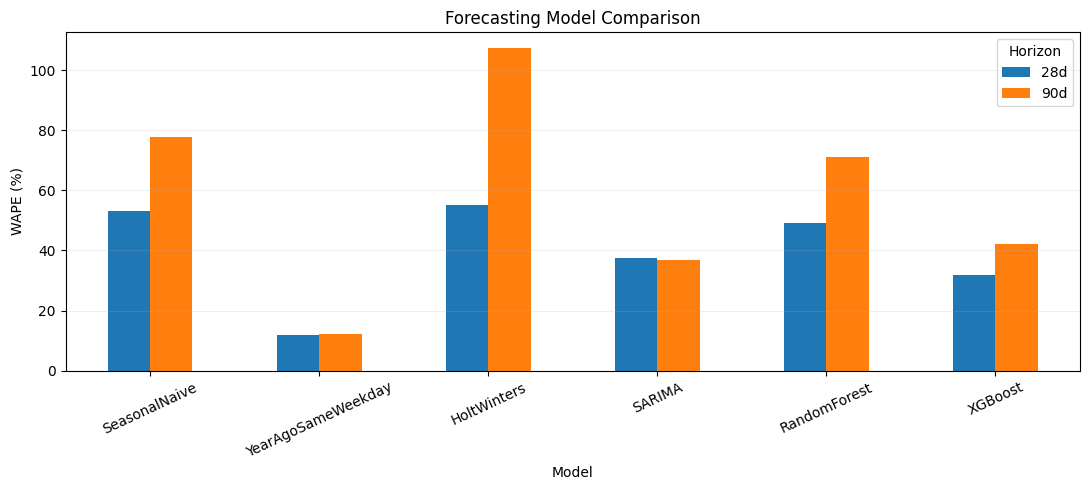

In [15]:
# ========================
# MODEL COMPARISON CHART
# ========================

compare = model_scores.pivot(
    index="Model",
    columns="Horizon",
    values="WAPE_pct"
)

compare = compare.reindex(
    ALL_MODELS
)

fig, ax = plt.subplots(
    figsize=(11, 5)
)

compare.plot(
    kind="bar",
    ax=ax
)

ax.set_title(
    "Forecasting Model Comparison"
)

ax.set_xlabel(
    "Model"
)

ax.set_ylabel(
    "WAPE (%)"
)

ax.tick_params(
    axis="x",
    labelrotation=25
)

ax.grid(
    axis="y",
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    OUT / "01_model_wape.png",
    dpi=160
)

plt.show()

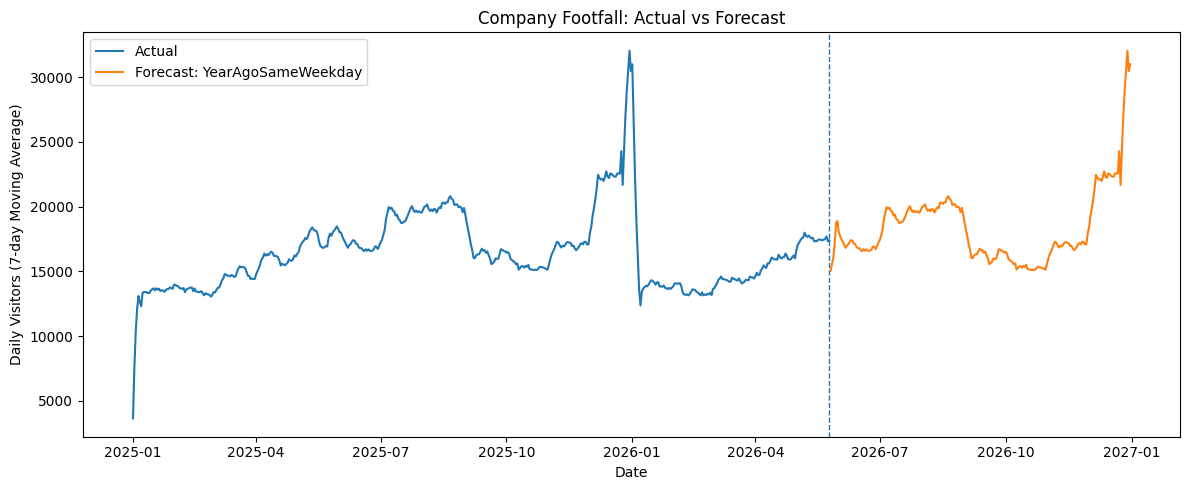

In [16]:
# ========================
# FOOTFALL VISUALIZATION
# ========================

company_daily = (
    full.groupby(
        ["Date", "Source"],
        as_index=False
    )["Visitors"]
    .sum()
)

fig, ax = plt.subplots(
    figsize=(12, 5)
)

for source, group in company_daily.groupby(
    "Source"
):

    group = group.sort_values("Date")

    smoothed = (
        group["Visitors"]
        .rolling(
            7,
            min_periods=1
        )
        .mean()
    )

    ax.plot(
        group["Date"],
        smoothed,
        label=source
    )

# Forecast start marker

ax.axvline(
    LAST_OBSERVED,
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Company Footfall: Actual vs Forecast"
)

ax.set_xlabel("Date")

ax.set_ylabel(
    "Daily Visitors (7-day Moving Average)"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    OUT / "02_footfall_forecast.png",
    dpi=160
)

plt.show()

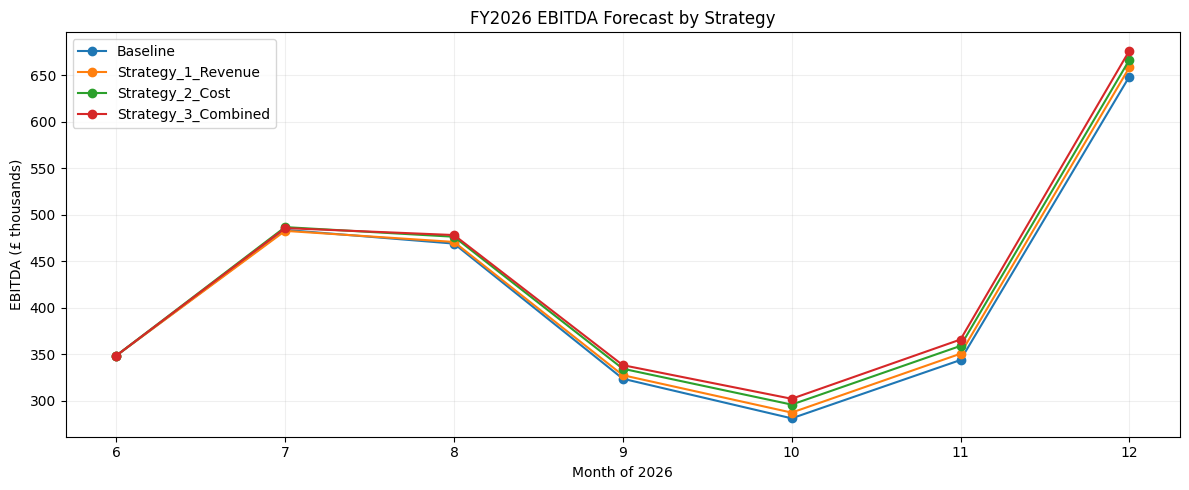

In [17]:
# ========================
# STRATEGIC EBITDA FORECAST
# ========================

fig, ax = plt.subplots(
    figsize=(12, 5)
)

for strategy, group in strategy_company.groupby(
    "Scenario"
):

    group = group.sort_values("Month")

    ax.plot(
        group["Month"],
        group["EBITDA"] / 1000,
        marker="o",
        label=strategy
    )

ax.set_title(
    "FY2026 EBITDA Forecast by Strategy"
)

ax.set_xlabel(
    "Month of 2026"
)

ax.set_ylabel(
    "EBITDA (£ thousands)"
)

ax.set_xticks(
    range(6, 13)
)

ax.grid(
    alpha=0.2
)

ax.legend()

plt.tight_layout()

plt.savefig(
    OUT / "03_strategy_ebitda.png",
    dpi=160
)

plt.show()

In [18]:
# ========================
# RUN SUMMARY
# ========================

summary = {

    "cutoff": "2026-06-01",

    "last_observed_footfall": "2026-05-25",

    "forecast_end": "2026-12-31",

    "champion_model": champion,

    "best_of_four_models": best_candidate,

    "actual_transactions": len(actual),

    "footfall_records": len(foot),

    "strategy_assumptions": {
        "revenue_gap_recovery": REV_GAP_RECOVERY,
        "cogs_gap_recovery": COGS_GAP_RECOVERY,
        "wage_gap_recovery": WAGE_GAP_RECOVERY,
        "extra_marketing": extra_marketing,
        "extra_training": extra_training
    },

    "notes": [
        "All FY2026 financial values are estimates.",
        "No FY2026 accounting actuals were provided.",
        "Forecast models use historical footfall.",
        "Strategy adjustments start in July 2026.",
        "No Bear/Base/Bull scenarios are included.",
        "No sensitivity analysis is included."
    ]
}

with open(
    OUT / "run_summary.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        indent=2,
        ensure_ascii=False
    )

print("\nALL BLOCKS COMPLETED")
print("Champion model:", champion)
print("Output folder:", OUT.resolve())

print("\nFINAL STRATEGY COMPARISON")

print(
    strategy_totals[
        [
            "Scenario",
            "Revenue",
            "EBITDA",
            "EBITDA_Margin",
            "Incremental_EBITDA"
        ]
    ]
    .round(2)
    .to_string(index=False)
)


ALL BLOCKS COMPLETED
Champion model: YearAgoSameWeekday
Output folder: C:\học tập\FP&A\dự án\fpa_2026_outputs

FINAL STRATEGY COMPARISON
           Scenario     Revenue     EBITDA  EBITDA_Margin  Incremental_EBITDA
           Baseline 11057659.41 2898339.28           0.26                0.00
 Strategy_1_Revenue 11135566.40 2925649.23           0.26            27309.95
    Strategy_2_Cost 11057659.41 2967330.49           0.27            68991.21
Strategy_3_Combined 11135566.40 2995025.17           0.27            96685.90


In [19]:

# ============================================
# BLOCK 12 - MACRO SCENARIO ENGINE
# ============================================

MACRO = {
    "Bear": {
        "demand": -0.05,
        "cogs": 0.02,
        "wages": 0.015
    },
    "Base": {
        "demand": 0.00,
        "cogs": 0.00,
        "wages": 0.00
    },
    "Bull": {
        "demand": 0.03,
        "cogs": -0.01,
        "wages": 0.00
    }
}

STRATEGY_NAMES = [
    "Baseline",
    "Strategy_1_Revenue",
    "Strategy_2_Cost",
    "Strategy_3_Combined"
]

# Reuse implementation costs from Block 10
implementation = strategy_site.set_index(
    ["Scenario", "Site_Code", "Month"]
)[[
    "Extra_Marketing_S1",
    "Extra_Training_S2"
]]


def evaluate_case(
    demand=0.0,
    cogs_shock=0.0,
    wages_shock=0.0,
    case="Custom"
):
    rows = []

    for _, r in baseline.loc[
        baseline["Month"].between(6, 12)
    ].iterrows():

        site = r["Site_Code"]
        month = int(r["Month"])
        ramp = STRATEGY_RAMP[month]

        # STEP 1: Adjust revenue for demand shock
        # Only F&B, Retail and Entertainment
        # are directly linked to footfall.

        rev_by_code = {
            code: float(r[f"Revenue_{code}"]) * (
                1 + demand
                if code in ["4000", "4010", "4020"]
                else 1.0
            )
            for code in rev_codes
        }

        # STEP 2: Adjust baseline costs

        base_fnb_cogs = (
            float(r["COGS_FNB"])
            * (1 + demand)
            * (1 + cogs_shock)
        )

        base_retail_cogs = (
            float(r["COGS_Retail"])
            * (1 + demand)
            * (1 + cogs_shock)
        )

        macro_cogs = (
            base_fnb_cogs + base_retail_cogs
        )

        macro_wages = (
            float(r["Wages"])
            * (1 + wages_shock)
        )

        fixed_opex = float(r["Fixed_OPEX"])
        base_variable_opex = float(r["Variable_OPEX"])

        # STEP 3: Evaluate each strategy

        for strategy in STRATEGY_NAMES:

            use_s1 = strategy in [
                "Strategy_1_Revenue",
                "Strategy_3_Combined"
            ]

            use_s2 = strategy in [
                "Strategy_2_Cost",
                "Strategy_3_Combined"
            ]

            # STRATEGY 1 - REVENUE

            extra_by_code = {
                code: (
                    rev_by_code[code]
                    * rev_lifts[code]
                    * ramp
                ) if use_s1 else 0.0
                for code in rev_codes
            }

            extra_revenue = sum(
                extra_by_code.values()
            )

            revenue = (
                sum(rev_by_code.values())
                + extra_revenue
            )

            # Incremental COGS from new sales

            fnb_ratio = (
                abs(base_fnb_cogs)
                / rev_by_code["4000"]
                if rev_by_code["4000"] > 0
                else 0.0
            )

            retail_ratio = (
                abs(base_retail_cogs)
                / rev_by_code["4010"]
                if rev_by_code["4010"] > 0
                else 0.0
            )

            extra_cogs = -(
                extra_by_code["4000"] * fnb_ratio
                + extra_by_code["4010"] * retail_ratio
            )

            cogs = macro_cogs + extra_cogs

            # STRATEGY 2 - COGS SAVINGS

            if use_s2:
                cogs += (
                    revenue
                    * cogs_ratio_reduction
                    * ramp
                )

            # STRATEGY 2 - WAGE SAVINGS

            wages = macro_wages

            if use_s2:
                wages += (
                    abs(wages)
                    * wage_saving_pct
                    * ramp
                )

            # VARIABLE OPEX

            variable_opex = base_variable_opex

            if use_s1:
                variable_opex -= (
                    extra_revenue
                    * historical_variable_opex_ratio
                )

            # Implementation costs from Block 10

            fees = implementation.loc[
                (strategy, site, month)
            ]

            variable_opex -= (
                float(fees["Extra_Marketing_S1"])
                + float(fees["Extra_Training_S2"])
            )

            # FINAL EBITDA

            ebitda = (
                revenue
                + cogs
                + wages
                + fixed_opex
                + variable_opex
            )

            rows.append({
                "Macro": case,
                "Strategy": strategy,
                "Site_Code": site,
                "Month": month,
                "Revenue": revenue,
                "COGS": cogs,
                "Wages": wages,
                "Fixed_OPEX": fixed_opex,
                "Variable_OPEX": variable_opex,
                "EBITDA": ebitda
            })

    return pd.DataFrame(rows)


# ============================================
# RECONCILIATION WITH BLOCK 10
# ============================================

check = evaluate_case(case="Base")

expected = strategy_site[[
    "Scenario",
    "Site_Code",
    "Month",
    "EBITDA"
]].rename(columns={
    "Scenario": "Strategy",
    "EBITDA": "Original_EBITDA"
})

check = check.merge(
    expected,
    on=["Strategy", "Site_Code", "Month"],
    validate="1:1"
)

assert np.allclose(
    check["EBITDA"],
    check["Original_EBITDA"],
    atol=0.01
), "Scenario results do not match Block 10"

print("Scenario engine ready.")
print("Base Case successfully reconciled.")


Scenario engine ready.
Base Case successfully reconciled.



SCENARIO ANALYSIS
Macro            Strategy     Revenue     EBITDA  EBITDA_Margin  No_Strategy_EBITDA  Incremental_EBITDA
 Base            Baseline 11057659.41 2898339.28           0.26          2898339.28                0.00
 Base  Strategy_1_Revenue 11135566.40 2925649.23           0.26          2898339.28            27309.95
 Base     Strategy_2_Cost 11057659.41 2967330.49           0.27          2898339.28            68991.21
 Base Strategy_3_Combined 11135566.40 2995025.17           0.27          2898339.28            96685.90
 Bear            Baseline 10591164.35 2463402.41           0.23          2463402.41                0.00
 Bear  Strategy_1_Revenue 10665943.63 2488463.66           0.23          2463402.41            25061.25
 Bear     Strategy_2_Cost 10591164.35 2531199.93           0.24          2463402.41            67797.51
 Bear Strategy_3_Combined 10665943.63 2556630.48           0.24          2463402.41            93228.06
 Bull            Baseline 11337556.45 3126764

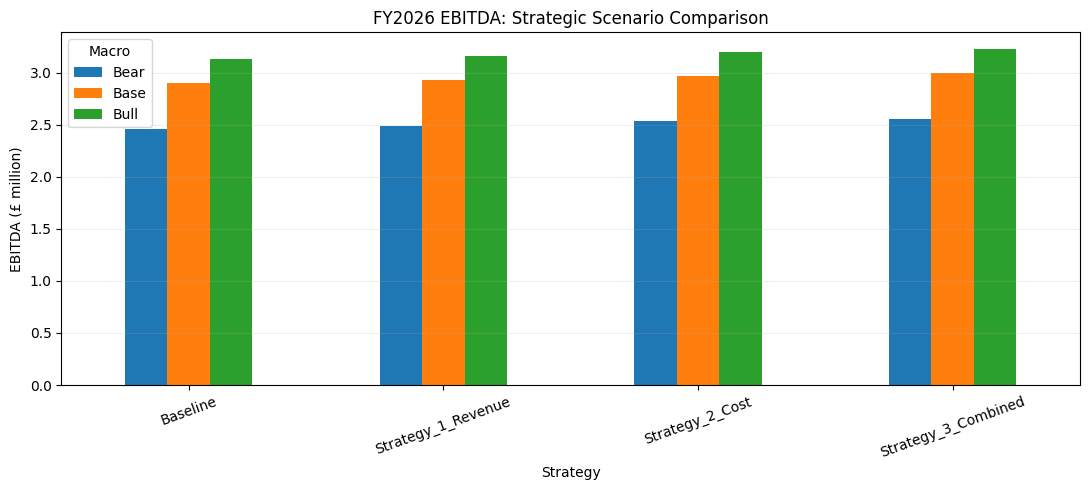

In [20]:

# ============================================
# BLOCK 13 - SCENARIO ANALYSIS
# ============================================

scenario_results = []

for scenario_name, assumptions in MACRO.items():

    result = evaluate_case(
        demand=assumptions["demand"],
        cogs_shock=assumptions["cogs"],
        wages_shock=assumptions["wages"],
        case=scenario_name
    )

    scenario_results.append(result)

scenario_detail = pd.concat(
    scenario_results,
    ignore_index=True
)

scenario_detail.to_csv(
    OUT / "12_scenario_site_monthly.csv",
    index=False
)

# ============================================
# AGGREGATE FINANCIAL PERFORMANCE
# ============================================

scenario_summary = (
    scenario_detail.groupby(
        ["Macro", "Strategy"],
        as_index=False
    )[["Revenue", "EBITDA"]].sum()
)

scenario_summary["EBITDA_Margin"] = (
    scenario_summary["EBITDA"]
    / scenario_summary["Revenue"]
)

# Compare each strategy with No Strategy
# under the SAME macro scenario.

no_strategy = scenario_summary.loc[
    scenario_summary["Strategy"] == "Baseline",
    ["Macro", "EBITDA"]
].rename(columns={
    "EBITDA": "No_Strategy_EBITDA"
})

scenario_summary = scenario_summary.merge(
    no_strategy,
    on="Macro",
    validate="m:1"
)

scenario_summary["Incremental_EBITDA"] = (
    scenario_summary["EBITDA"]
    - scenario_summary["No_Strategy_EBITDA"]
)

print("\nSCENARIO ANALYSIS")
print(
    scenario_summary.round(2).to_string(
        index=False
    )
)

scenario_summary.to_csv(
    OUT / "13_scenario_strategy_summary.csv",
    index=False
)

# ============================================
# EXTRACT BASE AND BEAR RESULTS
# ============================================

base_case = scenario_summary[
    scenario_summary["Macro"] == "Base"
].set_index("Strategy")

bear_case = scenario_summary[
    scenario_summary["Macro"] == "Bear"
].set_index("Strategy")

# ============================================
# FOUR CRITERIA FOR DECISION
# ============================================

decision = pd.DataFrame({

    "Base_EBITDA":
        base_case["EBITDA"],

    "Base_EBITDA_Margin":
        base_case["EBITDA_Margin"],

    "Base_Incremental_EBITDA":
        base_case["Incremental_EBITDA"],

    "Bear_EBITDA":
        bear_case["EBITDA"],

    "Bear_Incremental_EBITDA":
        bear_case["Incremental_EBITDA"],

    "Bear_EBITDA_Margin":
        bear_case["EBITDA_Margin"]
})

# Exclude baseline from strategy ranking
decision = decision.drop(
    index="Baseline"
)

# All 4 criteria: higher is better

criteria = [
    "Base_EBITDA",
    "Base_EBITDA_Margin",
    "Base_Incremental_EBITDA",
    "Bear_EBITDA"
]

decision["Rank_Sum"] = (
    decision[criteria]
    .rank(
        ascending=False,
        method="min"
    )
    .sum(axis=1)
)

decision = decision.sort_values(
    [
        "Rank_Sum",
        "Bear_Incremental_EBITDA"
    ],
    ascending=[True, False]
)

# ============================================
# FINAL SELECTION
# ============================================

selected_strategy = decision.index[0]

print("\nSTRATEGY RANKING")
print(
    decision.round(3).to_string()
)

print("\nSELECTED STRATEGY:")
print(selected_strategy)

decision.to_csv(
    OUT / "13_strategy_decision.csv"
)

# ============================================
# SCENARIO COMPARISON CHART
# ============================================

chart_data = scenario_summary.pivot(
    index="Strategy",
    columns="Macro",
    values="EBITDA"
)

chart_data = (
    chart_data[["Bear", "Base", "Bull"]]
    / 1_000_000
)

fig, ax = plt.subplots(figsize=(11, 5))

chart_data.plot(
    kind="bar",
    ax=ax
)

ax.set_title(
    "FY2026 EBITDA: Strategic Scenario Comparison"
)
ax.set_xlabel("Strategy")
ax.set_ylabel("EBITDA (£ million)")
ax.tick_params(axis="x", labelrotation=20)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    OUT / "13_scenario_comparison.png",
    dpi=160
)

plt.show()



ROBUSTNESS TEST
Strategy
Strategy_3_Combined    25
Name: count, dtype: int64

Selected strategy: Strategy_3_Combined

EBITDA SENSITIVITY MATRIX
COGS_Cost_Shock      -0.01       0.00       0.01       0.02       0.03
Demand_Shock                                                          
-0.08            2476138.0  2451904.0  2427671.0  2403438.0  2379204.0
-0.05            2680598.0  2655575.0  2630551.0  2605527.0  2580504.0
-0.03            2816905.0  2791355.0  2765804.0  2740254.0  2714704.0
 0.00            3021366.0  2995025.0  2968685.0  2942344.0  2916003.0
 0.03            3225826.0  3198696.0  3171565.0  3144434.0  3117303.0


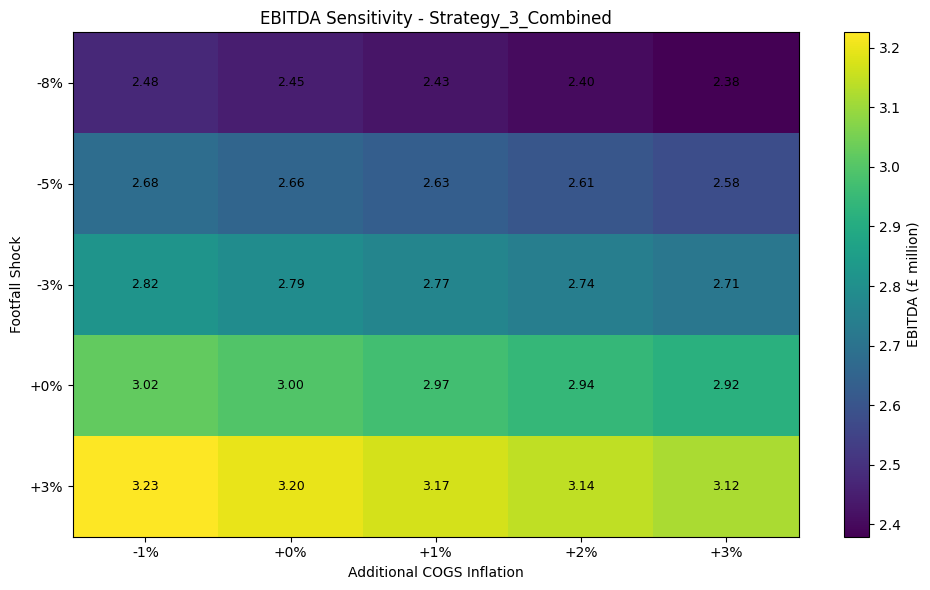


FINAL DECISION
Recommended Strategy: Strategy_3_Combined
Best EBITDA in sensitivity cases: 25/25
Base EBITDA: 2995025.17
Base EBITDA Margin: 26.9 %
Incremental EBITDA: 96685.9
Bear Case EBITDA: 2556630.48

Scenario & Sensitivity Analysis completed.


In [21]:

# ============================================
# BLOCK 14 - SENSITIVITY ANALYSIS
# ============================================

DEMAND_SHOCKS = [
    -0.08,
    -0.05,
    -0.03,
    0.00,
    0.03
]

COGS_SHOCKS = [
    -0.01,
    0.00,
    0.01,
    0.02,
    0.03
]

sensitivity_records = []

# ============================================
# 25 COMBINATIONS
# ============================================

for demand in DEMAND_SHOCKS:

    for cogs_shock in COGS_SHOCKS:

        result = evaluate_case(
            demand=demand,
            cogs_shock=cogs_shock,
            wages_shock=0.0
        )

        result_summary = (
            result.groupby("Strategy")[
                ["Revenue", "EBITDA"]
            ].sum()
        )

        base_ebitda = result_summary.loc[
            "Baseline", "EBITDA"
        ]

        for strategy, r in result_summary.iterrows():

            sensitivity_records.append({

                "Demand_Shock": demand,
                "COGS_Cost_Shock": cogs_shock,
                "Strategy": strategy,

                "Revenue": r["Revenue"],
                "EBITDA": r["EBITDA"],

                "EBITDA_Margin": (
                    r["EBITDA"] / r["Revenue"]
                ),

                "Incremental_EBITDA": (
                    r["EBITDA"] - base_ebitda
                )
            })

sensitivity = pd.DataFrame(
    sensitivity_records
)

sensitivity.to_csv(
    OUT / "14_sensitivity_all_strategies.csv",
    index=False
)

# ============================================
# ROBUSTNESS TEST
# ============================================

# Which strategy generates the highest
# EBITDA in each of the 25 combinations?

best_by_case = (
    sensitivity.loc[
        sensitivity["Strategy"] != "Baseline"
    ]
    .sort_values(
        "EBITDA",
        ascending=False
    )
    .drop_duplicates(
        ["Demand_Shock", "COGS_Cost_Shock"]
    )
)

robustness = (
    best_by_case["Strategy"]
    .value_counts()
)

print("\nROBUSTNESS TEST")
print(robustness)

print("\nSelected strategy:", selected_strategy)

# ============================================
# EBITDA SENSITIVITY MATRIX
# ============================================

heatmap_data = (
    sensitivity.loc[
        sensitivity["Strategy"] == selected_strategy
    ]
    .pivot(
        index="Demand_Shock",
        columns="COGS_Cost_Shock",
        values="EBITDA"
    )
    .sort_index()
    .sort_index(axis=1)
)

print("\nEBITDA SENSITIVITY MATRIX")
print(
    heatmap_data.round(0).to_string()
)

# ============================================
# SENSITIVITY HEATMAP
# ============================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)

values = heatmap_data.to_numpy() / 1e6

im = ax.imshow(
    values,
    aspect="auto"
)

ax.set_xticks(
    range(len(heatmap_data.columns)),
    [f"{x:+.0%}" for x in heatmap_data.columns]
)

ax.set_yticks(
    range(len(heatmap_data.index)),
    [f"{x:+.0%}" for x in heatmap_data.index]
)

ax.set_xlabel(
    "Additional COGS Inflation"
)

ax.set_ylabel(
    "Footfall Shock"
)

ax.set_title(
    f"EBITDA Sensitivity - {selected_strategy}"
)

# Display values inside cells

for i in range(values.shape[0]):

    for j in range(values.shape[1]):

        ax.text(
            j,
            i,
            f"{values[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

fig.colorbar(
    im,
    ax=ax,
    label="EBITDA (£ million)"
)

plt.tight_layout()

plt.savefig(
    OUT / "14_ebitda_sensitivity.png",
    dpi=160
)

plt.show()

# ============================================
# FINAL STRATEGIC DECISION
# ============================================

best_count = int(
    robustness.get(selected_strategy, 0)
)

total_cases = len(DEMAND_SHOCKS) * len(COGS_SHOCKS)

print("\nFINAL DECISION")
print("Recommended Strategy:", selected_strategy)

print(
    "Best EBITDA in sensitivity cases:",
    f"{best_count}/{total_cases}"
)

print(
    "Base EBITDA:",
    round(decision.loc[
        selected_strategy, "Base_EBITDA"
    ], 2)
)

print(
    "Base EBITDA Margin:",
    round(
        decision.loc[
            selected_strategy, "Base_EBITDA_Margin"
        ] * 100, 2
    ),
    "%"
)

print(
    "Incremental EBITDA:",
    round(decision.loc[
        selected_strategy, "Base_Incremental_EBITDA"
    ], 2)
)

print(
    "Bear Case EBITDA:",
    round(decision.loc[
        selected_strategy, "Bear_EBITDA"
    ], 2)
)

print("\nScenario & Sensitivity Analysis completed.")
